# Análise exploratória
Análise sobre o dataset 911.csv

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|



In [502]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['figure.dpi'] = 150

import seaborn as sns
from IPython.core.pylabtools import figsize
from matplotlib.ticker import FormatStrFormatter

In [476]:
df = pd.read_csv('../../input/911.csv', encoding='utf-8', quotechar='"')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99492 entries, 0 to 99491
Data columns (total 9 columns):
lat          99492 non-null float64
lng          99492 non-null float64
desc         99492 non-null object
zip          86637 non-null float64
title        99492 non-null object
timeStamp    99492 non-null object
twp          99449 non-null object
addr         98973 non-null object
e            99492 non-null int64
dtypes: float64(3), int64(1), object(5)
memory usage: 6.8+ MB


A coluna title foi dividida em 'service' e 'subService'

In [477]:
df['service'] = [words.split(sep=':')[0] for words in np.array(df.loc[:,'title'])]
df['subService'] = [words.split(sep=':')[1] for words in np.array(df.loc[:,'title'])]

In [478]:
df.service.value_counts()

EMS        48877
Traffic    35695
Fire       14920
Name: service, dtype: int64

In [479]:
df.groupby(by='service').subService.value_counts()

service  subService                   
EMS       RESPIRATORY EMERGENCY            5112
          CARDIAC EMERGENCY                5012
          FALL VICTIM                      4863
          VEHICLE ACCIDENT                 3935
          SUBJECT IN PAIN                  2687
          HEAD INJURY                      2631
          UNKNOWN MEDICAL EMERGENCY        1873
          SYNCOPAL EPISODE                 1717
          SEIZURES                         1630
          GENERAL WEAKNESS                 1464
          ABDOMINAL PAINS                  1436
          ALTERED MENTAL STATUS            1386
          MEDICAL ALERT ALARM              1342
          HEMORRHAGING                     1259
          CVA/STROKE                       1202
          OVERDOSE                         1191
          NAUSEA/VOMITING                  1131
          UNCONSCIOUS SUBJECT              1115
          DIABETIC EMERGENCY                836
          DIZZINESS                         799
 

Convertendo campo 'timeStamp' para datetime e gerando novas colunas como 'hour', 'month' e 'dayOfWeek'

In [480]:
df.timeStamp = pd.to_datetime(df.timeStamp);df['hour'] = df.timeStamp.dt.hour;
df['month'] = df.timeStamp.dt.month;df['dayOfWeek'] = df.timeStamp.dt.dayofweek;
print('Dados entre ' + str(df.timeStamp.dt.date.min()) + ' a ' + str(df.timeStamp.dt.date.max()))

Dados entre 2015-12-10 a 2016-08-24


In [481]:
df[df['service']=='EMS'].groupby(['month','subService']).size().reset_index(name='total')

,month,subService,total
0,1,ABDOMINAL PAINS,186
1,1,ALLERGIC REACTION,45
2,1,ALTERED MENTAL STATUS,160
3,1,AMPUTATION,4
4,1,ANIMAL BITE,8
5,1,APPLIANCE FIRE,1
6,1,ASSAULT VICTIM,60
7,1,BACK PAINS/INJURY,108
8,1,BUILDING FIRE,23
9,1,BURN VICTIM,3


In [482]:
ttt = df[df['service']=='EMS'].groupby(['month']).size()
ttt.sort_values()

month
12    3898
8     4508
2     5413
4     5680
6     5720
5     5734
3     5832
7     6029
1     6063
dtype: int64

In [483]:
df.groupby(['hour']).size()

hour
0     2112
1     1721
2     1549
3     1435
4     1418
5     1629
6     2513
7     3970
8     5044
9     5314
10    5413
11    5543
12    6029
13    5967
14    5997
15    6154
16    6490
17    6517
18    5762
19    4908
20    4377
21    3788
22    3283
23    2559
dtype: int64

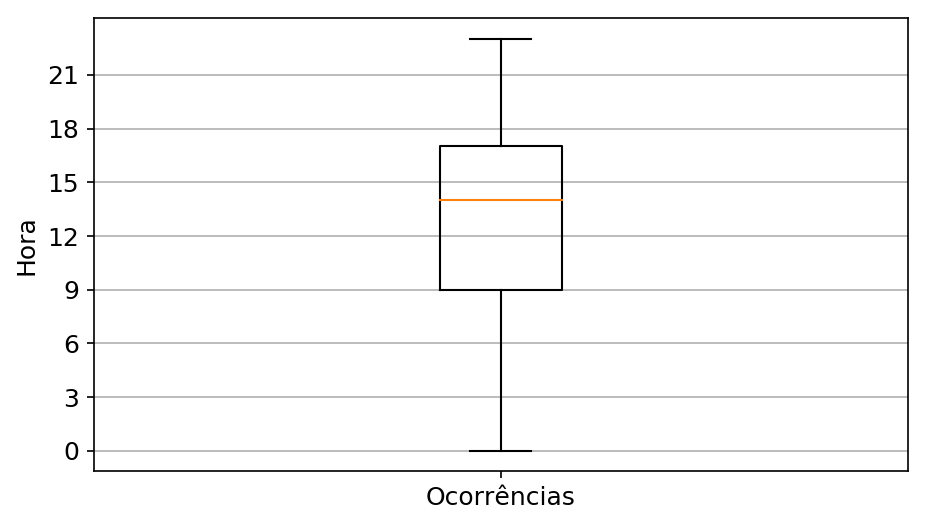

In [507]:
figsize(7,4);plt.boxplot(df['hour'],labels=['Ocorrências']);plt.ylabel('Hora')
plt.yticks(np.arange(0, 24, step=3));plt.grid(axis='y');plt.show()

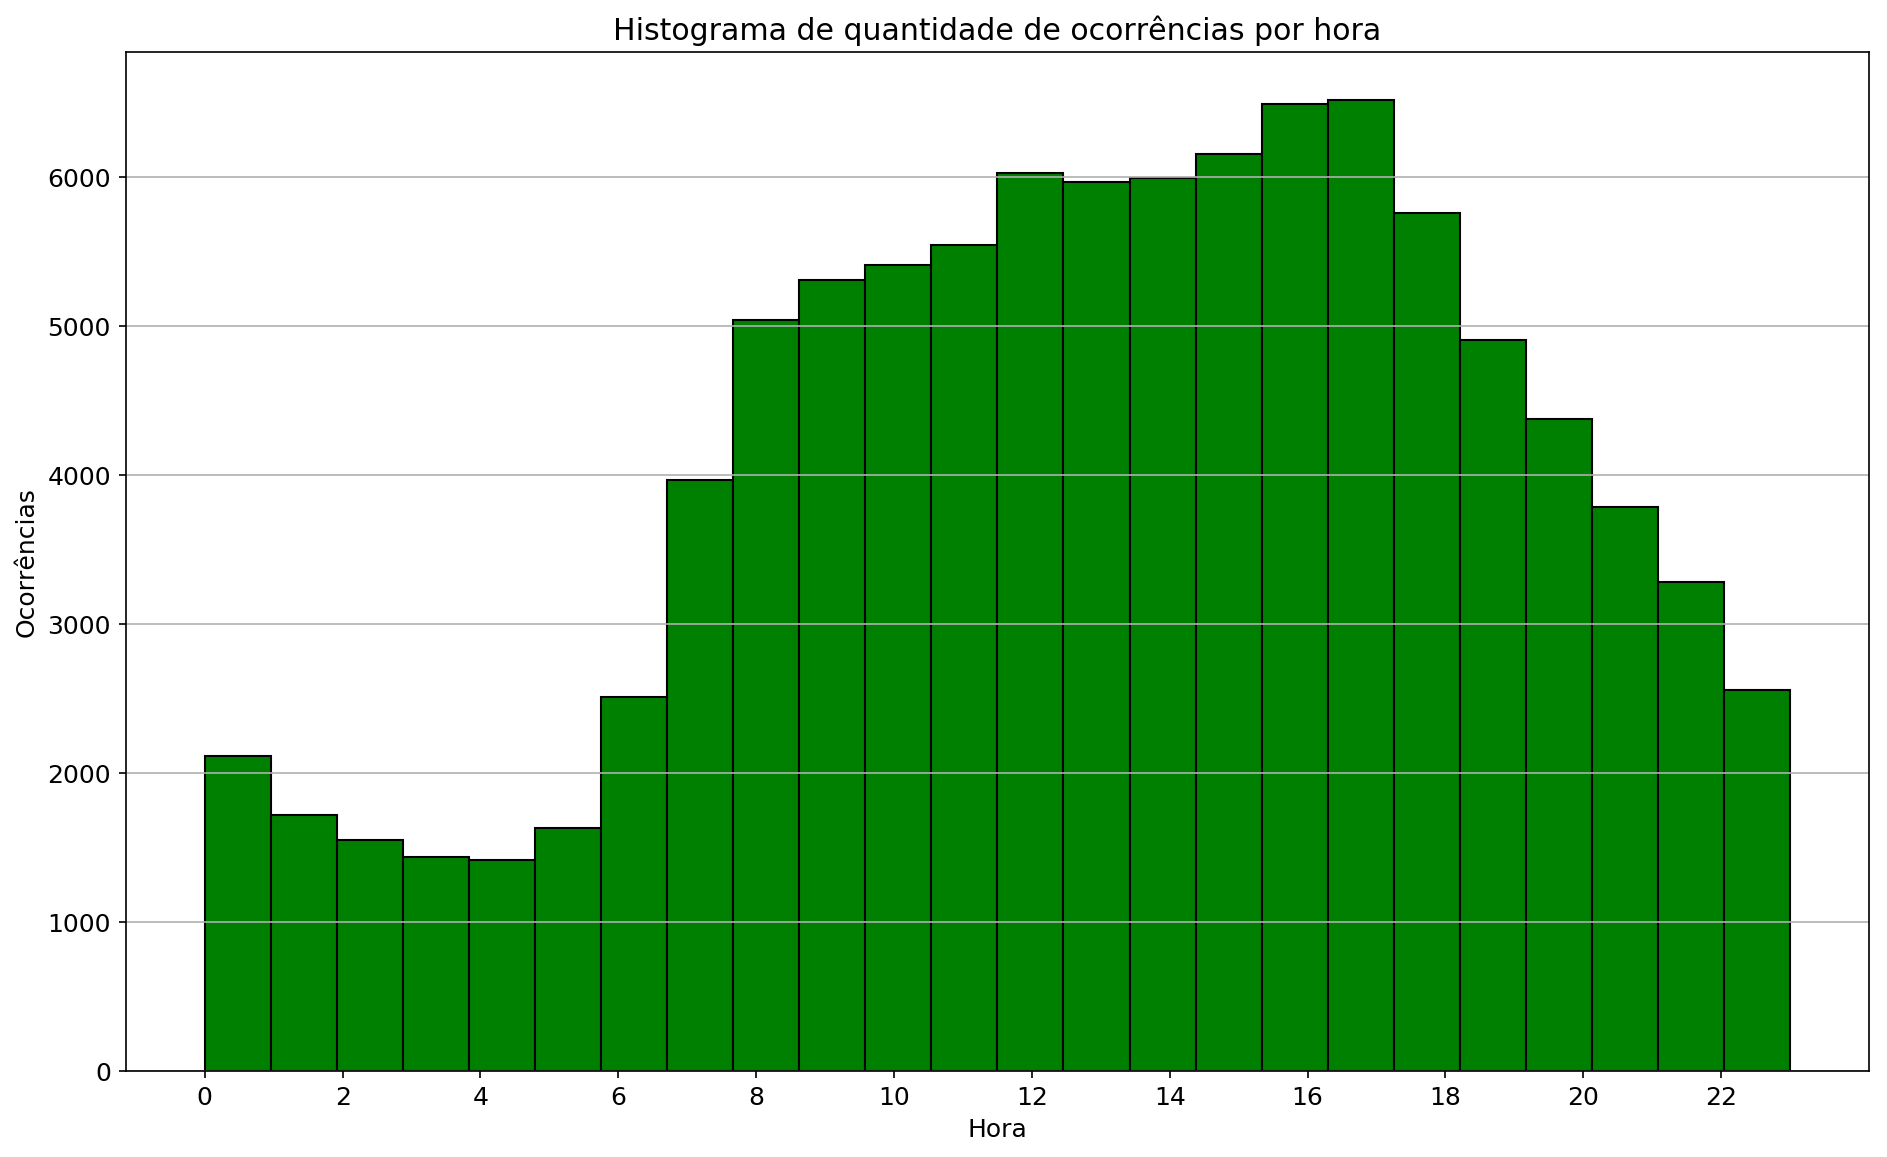

In [485]:
figsize(15,9)
plt.hist(df.hour, color = 'green', edgecolor = 'black',
         bins = int(195/8))

plt.title('Histograma de quantidade de ocorrências por hora')
plt.xlabel('Hora'); 
plt.ylabel('Ocorrências');
plt.xticks(np.arange(0, 24, step=2))
plt.grid(axis='y')

In [486]:
services = df.groupby('service')['service'].count().sort_values(ascending=False).index[:]
services

Index(['EMS', 'Traffic', 'Fire'], dtype='object', name='service')

In [487]:
figsize(7, 3)

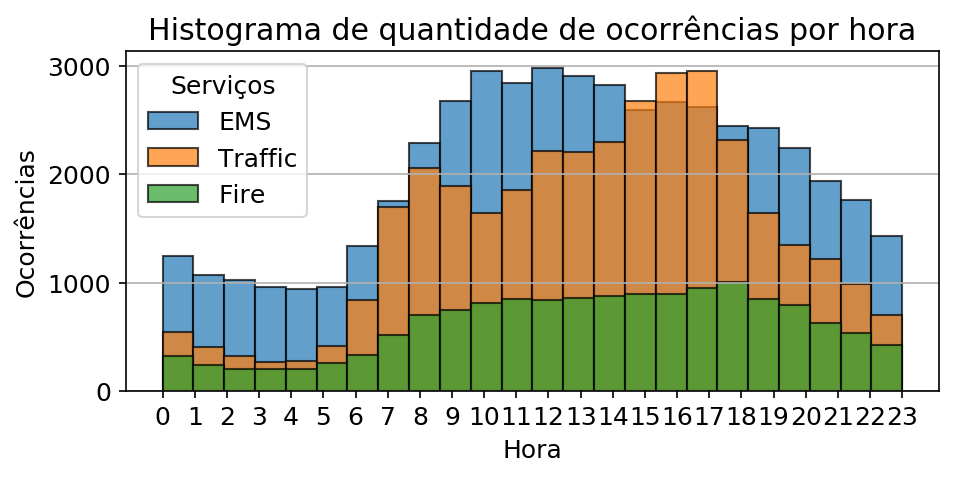

In [488]:
for srv in services:
    subset = df[df['service'] == srv];plt.hist(subset['hour'], edgecolor = 'black',alpha=0.7,bins = int(195/8), label = srv)
plt.legend(prop={'size': 12}, title = 'Serviços');plt.title('Histograma de quantidade de ocorrências por hora');plt.xlabel('Hora'); plt.ylabel('Ocorrências');plt.xticks(np.arange(0, 24, step=1));plt.grid(axis='y')

In [489]:
totalService = df.groupby('month')['service'].count().sort_index(ascending=False)
totalEMS = df[df['service']=='EMS'].groupby('month')['service'].count().sort_index(ascending=False)
totalTrafic = df[df['service']=='Traffic'].groupby('month')['service'].count().sort_index(ascending=False)
totalFire = df[df['service']=='Fire'].groupby('month')['service'].count().sort_index(ascending=False)
figsize(7,4)

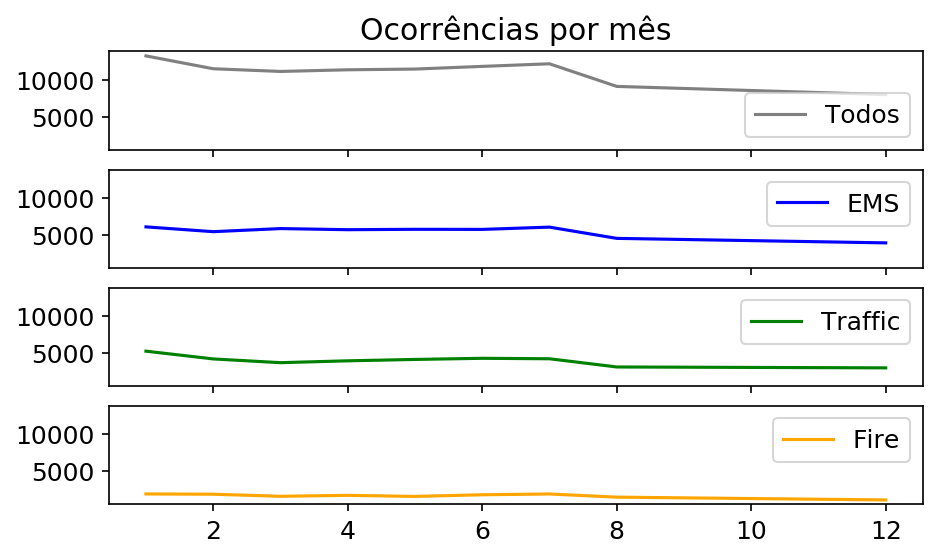

In [490]:
f, (ax0, ax1, ax2, ax3) = plt.subplots(4, sharex=True, sharey=True);ax0.set_title('Ocorrências por mês');ax0.plot(totalService , color='gray');ax0.legend(('Todos',),loc='lower right', prop={'size': 12});ax1.plot(totalEMS , color='blue');ax1.legend(('EMS',),loc='upper right', prop={'size': 12});ax2.plot(totalTrafic, color='green', label='Traffic');ax2.legend(('Traffic',), loc='upper right', prop={'size': 12});ax3.plot(totalFire, color='orange');ax3.legend(('Fire',), loc='upper right', prop={'size': 12});plt.setp([a.get_xticklabels() for a in f.axes[:-1]], visible=False)

In [491]:
all = [totalService,totalEMS,totalTrafic,totalFire]

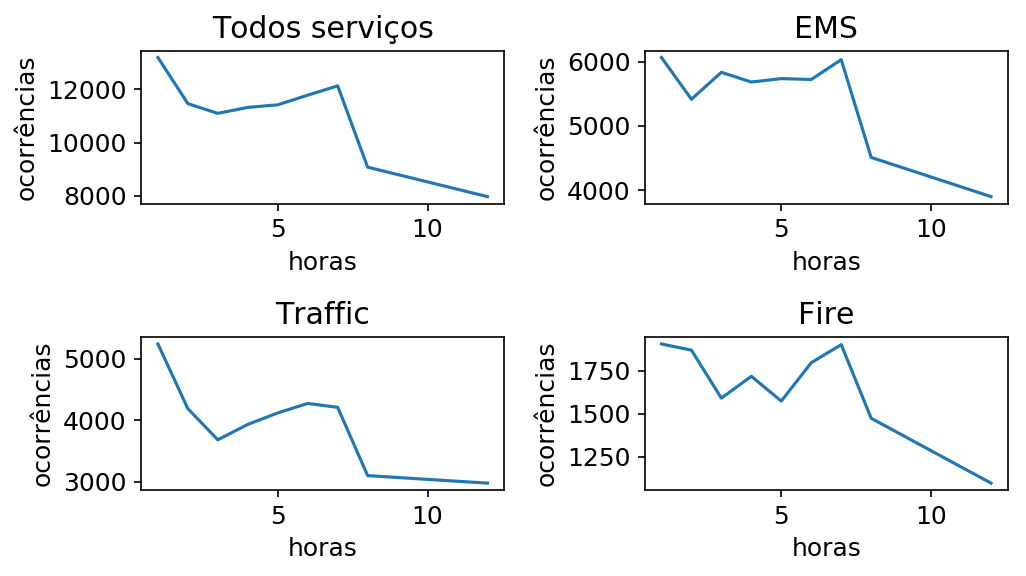

In [492]:
names = ['Todos serviços', 'EMS', 'Traffic', 'Fire']

figs, axes = plt.subplots(nrows=2,ncols=2)
idx = 0
for ir, row in enumerate(axes):
    for ic, col in enumerate(row):
        col.plot(all[idx])
        col.set_title(names[idx])  
        col.set_xlabel('horas')
        col.set_ylabel('ocorrências')
        idx+=1
                
figs.tight_layout()            
plt.show()

In [493]:
coordenadaOcr = pd.DataFrame(df.groupby(['lat','lng']).e.value_counts().nlargest(100).sort_values(ascending=True).reset_index(name='total'))

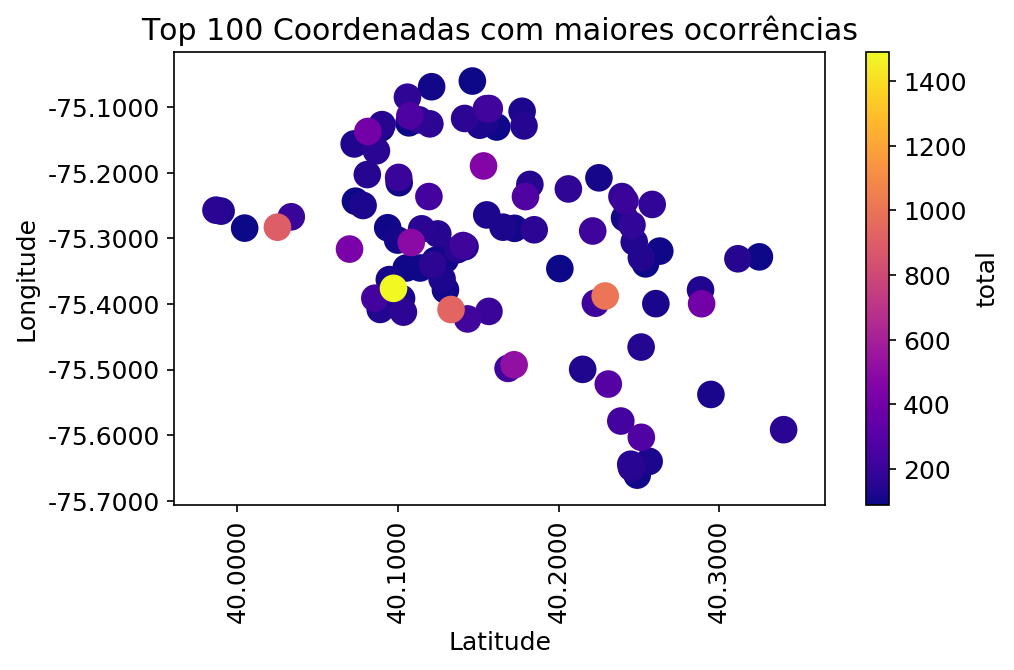

In [508]:
figsize(7,4); fig, ax = plt.subplots(); ax.yaxis.set_major_formatter(FormatStrFormatter('%.4f'));ax.xaxis.set_major_formatter(FormatStrFormatter('%.4f')) ;coordenadaOcr.plot(kind="scatter", x='lat', y='lng', c='total', s=150, cmap="plasma", ax=ax,rot=90);plt.xlabel('Latitude');plt.ylabel('Longitude');plt.title('Top 100 Coordenadas com maiores ocorrências');plt.show()

In [495]:
topTwp = df.groupby('twp').size().sort_values(ascending=False).nlargest(5)

In [496]:
data = topTwp.reset_index(name='total');
sizes = list(data.total);
labels = list(data.twp)
def absValue(val):
    a  = np.round(val/100.*data.total.sum(), 0)
    return a

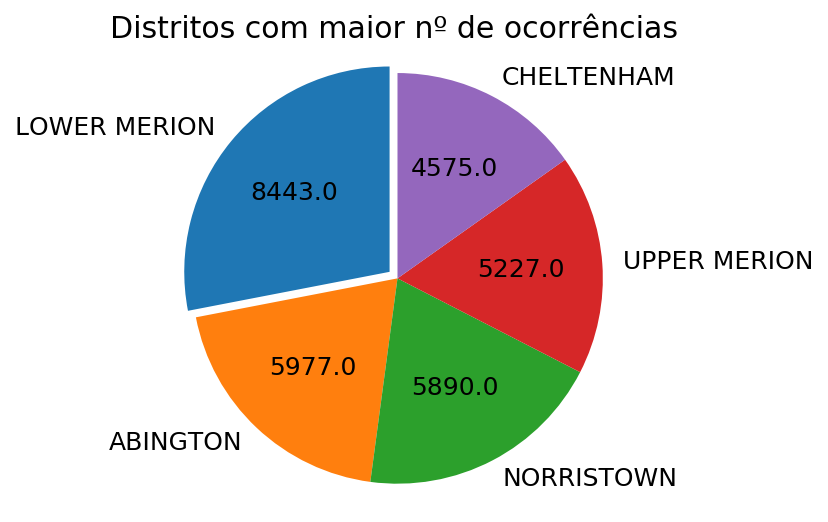

In [497]:
figsize(4,4);explode = (0.05, 0, 0, 0,0);fig1, ax1 = plt.subplots();ax1.pie(sizes,explode, labels=labels, autopct=absValue, shadow=False,pctdistance=0.6, startangle=90)
ax1.axis('equal');plt.title('Distritos com maior nº de ocorrências');plt.show()

In [498]:
fiveEMS = pd.DataFrame(df[df['service']=='EMS'].groupby('subService').size().nlargest(5).reset_index(name='total'))
fiveFire = pd.DataFrame(df[df['service']=='Fire'].groupby('subService').size().nlargest(5).reset_index(name='total'))
fiveTraffic = pd.DataFrame(df[df['service']=='Traffic'].groupby('subService').size().nlargest(5).reset_index(name='total'))